# Zadanie 1 — PenDigits

**Cel:** poznaj numeryczny zbiór danych, porównaj kilka uzasadnionych metod klasyfikacji statystycznej i uczenia maszynowego oraz oceń, czy większa złożoność modelu daje istotną korzyść.

In [33]:
# Proponowane importy — możesz je zmienić lub rozszerzyć.
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from huggingface_hub import hf_hub_download
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
import time
import pickle
from sklearn.base import clone


In [34]:
# Pobranie niezmienionego archiwum z oficjalnymi podziałami train/test.
DATA_DIR = Path("data/zadanie-1")
DATA_DIR.mkdir(parents=True, exist_ok=True)

archive_path = hf_hub_download(
    repo_id="AI-MED-AGH/Recruitment-Task-1",
    filename="original/pen+based+recognition+of+handwritten+digits.zip",
    repo_type="dataset",
    local_dir=DATA_DIR,
)
with ZipFile(archive_path) as archive:
    archive.extractall(DATA_DIR / "pendigits")

print(f"Dane zapisano w: {DATA_DIR / 'pendigits'}")

Dane zapisano w: data\zadanie-1\pendigits


## A — Poznanie i przygotowanie danych

Rozpoznaj zmienną docelową i cechy, sprawdź rozkład klas, braki, duplikaty oraz zakresy wartości. Pokaż krótką eksplorację danych i uzasadnij preprocessing. Zachowaj oficjalny podział danych; nie zastępuj go losowym podziałem.

In [35]:
PEN_DIR = DATA_DIR / "pendigits"
cols = [f"{c}{i}" for i in range(1, 9) for c in ("x", "y")] + ["digit"]

train = pd.read_csv(PEN_DIR / "pendigits.tra", header=None, names=cols)
test  = pd.read_csv(PEN_DIR / "pendigits.tes", header=None, names=cols)

FEATURES = cols[:-1]
TARGET = "digit"
print(train.shape, test.shape)
train.head()

(7494, 17) (3498, 17)


,x1,y1,x2,y2,x3,y3,x4,y4,x5,y5,x6,y6,x7,y7,x8,y8,digit
0,47,100,27,81,57,37,26,0,0,23,56,53,100,90,40,98,8
1,0,89,27,100,42,75,29,45,15,15,37,0,69,2,100,6,2
2,0,57,31,68,72,90,100,100,76,75,50,51,28,25,16,0,1
3,0,100,7,92,5,68,19,45,86,34,100,45,74,23,67,0,4
4,0,67,49,83,100,100,81,80,60,60,40,40,33,20,47,0,1


In [36]:
print(f'Braki train i test: {train.isna().sum().sum()} i {test.isna().sum().sum()}')
print(f'Duplikaty train i test: {train.duplicated().sum()} i {test.duplicated().sum()}')
print(f'Wspólne wiersze train-test: {len(train.merge(test, how="inner"))}')
print(f'Unikalne wartości w digit w trai i test: {np.sort(train[TARGET].unique())} i {np.sort(test[TARGET].unique())}')
print("Zakres cech train:", train[FEATURES].min().min(), "-", train[FEATURES].max().max())
train[FEATURES].describe().T

Braki train i test: 0 i 0
Duplikaty train i test: 0 i 0
Wspólne wiersze train-test: 0
Unikalne wartości w digit w trai i test: [0 1 2 3 4 5 6 7 8 9] i [0 1 2 3 4 5 6 7 8 9]
Zakres cech train: 0 - 100


,count,mean,std,min,25%,50%,75%,max
x1,7494.0,37.384307,33.322024,0.0,5.0,31.0,61.0,100.0
y1,7494.0,84.679343,16.848420,0.0,76.0,89.0,100.0,100.0
x2,7494.0,40.005604,26.256025,0.0,20.0,39.0,58.0,100.0
y2,7494.0,82.889512,19.638582,0.0,70.0,89.0,100.0,100.0
x3,7494.0,50.878303,34.927201,0.0,17.0,56.0,81.0,100.0
y3,7494.0,65.044436,27.377341,0.0,48.0,71.0,86.0,100.0
x4,7494.0,51.471844,30.680075,0.0,28.0,54.0,75.0,100.0
y4,7494.0,44.599680,30.659478,0.0,22.0,42.0,65.0,100.0
x5,7494.0,57.129971,33.680340,0.0,30.0,60.0,88.0,100.0
y5,7494.0,34.069122,27.459989,0.0,7.0,33.0,55.0,100.0


In [37]:
print("Zakres cech test:", test[FEATURES].min().min(), "-", test[FEATURES].max().max())
test[FEATURES].describe().T

Zakres cech test: 0 - 100


,count,mean,std,min,25%,50%,75%,max
x1,3498.0,41.877930,35.995293,0.0,8.0,34.0,75.0,100.0
y1,3498.0,86.064894,14.737085,0.0,77.0,90.0,100.0,100.0
x2,3498.0,41.891081,26.486364,0.0,22.0,42.0,60.0,100.0
y2,3498.0,85.669525,17.960876,0.0,75.0,94.0,100.0,100.0
x3,3498.0,47.396798,32.134722,0.0,19.0,49.0,73.0,100.0
y3,3498.0,66.705832,26.130413,0.0,52.0,71.0,87.0,100.0
x4,3498.0,50.681246,30.351970,0.0,29.0,52.0,73.0,100.0
y4,3498.0,44.283305,28.227548,0.0,26.0,44.0,63.0,100.0
x5,3498.0,56.308462,35.089176,0.0,26.0,59.0,91.0,100.0
y5,3498.0,32.896512,26.785929,0.0,6.0,32.0,52.0,100.0


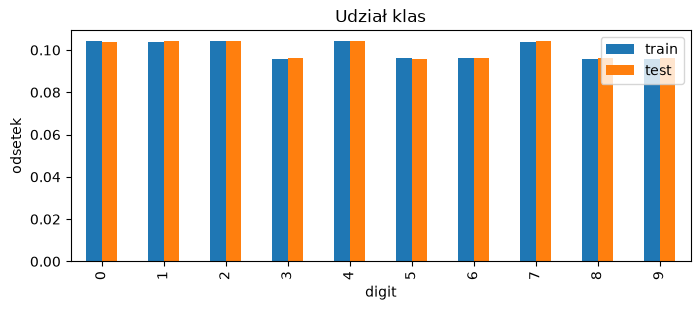

In [38]:
dist = pd.DataFrame({
    "train": train[TARGET].value_counts(normalize=True).sort_index(),
    "test":  test[TARGET].value_counts(normalize=True).sort_index(),
})
dist.plot.bar(figsize=(8, 3), title="Udział klas")
plt.ylabel("odsetek")
plt.show()

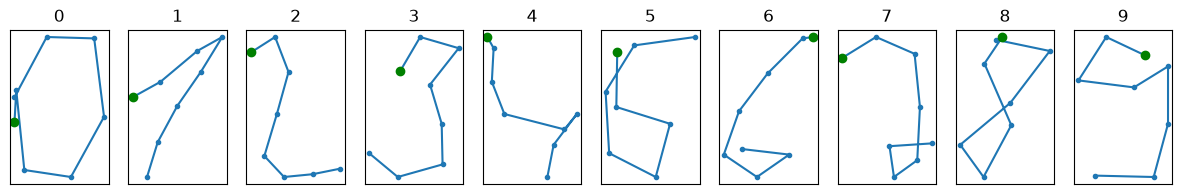

In [39]:
fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for d, ax in zip(range(10), axes):
    row = train[train[TARGET] == d].iloc[0]
    x, y = row[FEATURES[0::2]].values, row[FEATURES[1::2]].values
    ax.plot(x, y, "-o", ms=3)
    ax.plot(x[0], y[0], "go")  # punkt startu
    ax.set_title(d); ax.set_xticks([]); ax.set_yticks([])
plt.show()

In [40]:
X_train, y_train = train[FEATURES], train[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

### **Wyjaśnienia**

- Zmienną docelową jest kolumna digit, która zawiera 9 klas: [0 1 2 3 4 5 6 7 8 9]. Udziały klas są zarówno w train jak i test datasetcie równomiernie rozłożone (ok. 10% każda klasa).
- Nie ma żadnych braków danych ani duplikatów więc nic nie zostało uzupełnione.
- Wszystkie chechy są w tym samym zakresie 0-100.
- Zostawiam oficjalny podział tak jak w treści zadania.
- Skalowanie zamierzam dobrać ze względu na model (Dla modeli opartych na odległościach czy gradiencie dodam StandardScaler)


## B — Modelowanie

Zbuduj prosty model bazowy i porównaj go z kilkoma klasyfikatorami statystycznymi lub klasycznego uczenia maszynowego. Wykonaj dobór modeli, strojenie i sposób zapobiegania wyciekowi danych. 

In [41]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Baseline (najczęstsza klasa)": Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]),
    "Regresja logistyczna": Pipeline([("scaler", StandardScaler()),
                                      ("clf", LogisticRegression(max_iter=2000))]),
    "kNN": Pipeline([("scaler", StandardScaler()), 
                     ("clf", KNeighborsClassifier())]),
    "SVM (RBF)": Pipeline([("scaler", StandardScaler()),   # radialna funkcja bazowa
                           ("clf", SVC())]),
    "Random Forest": Pipeline([("clf", RandomForestClassifier(random_state=42, n_jobs=-1))])

}

results = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv,
                            scoring=["accuracy", "f1_macro"])
    results.append({
        "model": name,
        "accuracy": scores["test_accuracy"].mean(),
        "f1_macro": scores["test_f1_macro"].mean(),
        "f1_std": scores["test_f1_macro"].std(),
    })

results_df = pd.DataFrame(results).sort_values("f1_macro", ascending=False)
results_df

,model,accuracy,f1_macro,f1_std
3,SVM (RBF),0.995730,0.995738,0.002254
2,kNN,0.992394,0.992457,0.002455
4,Random Forest,0.991727,0.991834,0.002204
1,Regresja logistyczna,0.961970,0.961646,0.002108
0,Baseline (najczęstsza klasa),0.104083,0.018854,0.000005


In [42]:
param_grids = {
    "SVM (RBF)": {"clf__C": [1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1]},
    "kNN": {"clf__n_neighbors": [1, 3, 5, 7, 9], "clf__weights": ["uniform", "distance"]},
}

best_models = {}
for name, grid in param_grids.items():
    search = GridSearchCV(models[name], grid, cv=cv, scoring="f1_macro", n_jobs=-1)
    search.fit(X_train, y_train)
    best_models[name] = search.best_estimator_
    print(f"{name}: {search.best_params_}  CV F1 = {search.best_score_:.4f}")

SVM (RBF): {'clf__C': 10, 'clf__gamma': 0.1}  CV F1 = 0.9968
kNN: {'clf__n_neighbors': 3, 'clf__weights': 'distance'}  CV F1 = 0.9946


## C — Porównanie i wnioski

Porównaj modele na oficjalnym zbiorze testowym za pomocą odpowiednich metryk liczbowych. Uwzględnij błędy oraz praktyczny koszt modeli, np. czas uczenia i inferencji albo liczbę parametrów. Odpowiedz, czy wzrost złożoności jest wart uzyskanej poprawy.

In [43]:
final_models = {
    "Baseline (najczęstsza klasa)": models["Baseline (najczęstsza klasa)"],
    "Regresja logistyczna": models["Regresja logistyczna"],
    "Random Forest": models["Random Forest"],
    "kNN (strojony)": best_models["kNN"],
    "SVM RBF (strojony)": best_models["SVM (RBF)"],
}

def model_size(pipe):
    """Miara złożoności zależna od typu modelu."""
    clf = pipe.named_steps["clf"]
    if isinstance(clf, LogisticRegression):
        return clf.coef_.size + clf.intercept_.size, "wagi"
    if isinstance(clf, SVC):
        return clf.support_vectors_.shape[0], "wektory nośne"
    if isinstance(clf, RandomForestClassifier):
        return sum(t.tree_.node_count for t in clf.estimators_), "węzły drzew"
    if isinstance(clf, KNeighborsClassifier):
        return clf.n_samples_fit_, "zapamiętane próbki"
    return 0, "-"

test_results = []
for name, model in final_models.items():
    model = clone(model)  # świeża kopia, żeby uczciwie zmierzyć czas uczenia
    t0 = time.perf_counter(); model.fit(X_train, y_train); fit_t = time.perf_counter() - t0
    t0 = time.perf_counter(); y_pred = model.predict(X_test); pred_t = time.perf_counter() - t0
    size, unit = model_size(model)
    test_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "f1_macro": f1_score(y_test, y_pred, average="macro"),
        "błędy": int((y_pred != y_test).sum()),
        "czas uczenia [s]": fit_t,
        "czas predykcji [ms/próbkę]": pred_t / len(X_test) * 1000,
        "rozmiar modelu [kB]": len(pickle.dumps(model)) / 1024,
        "złożoność": f"{size} {unit}",
    })

test_df = pd.DataFrame(test_results).sort_values("f1_macro", ascending=False)
test_df.round(4)

,model,accuracy,f1_macro,błędy,czas uczenia [s],czas predykcji [ms/próbkę],rozmiar modelu [kB],złożoność
4,SVM RBF (strojony),0.9806,0.9805,68,0.2582,0.0849,194.5986,961 wektory nośne
3,kNN (strojony),0.9746,0.9747,89,0.0082,0.0164,996.9258,7494 zapamiętane próbki
2,Random Forest,0.9640,0.9644,126,0.3842,0.0154,8531.6348,60394 węzły drzew
1,Regresja logistyczna,0.9160,0.9164,294,0.3249,0.0013,2.9707,170 wagi
0,Baseline (najczęstsza klasa),0.1038,0.0188,3135,0.0030,0.0002,0.8545,0 -


              precision    recall  f1-score   support

           0      0.997     0.967     0.982       363
           1      0.968     0.989     0.978       364
           2      0.992     1.000     0.996       364
           3      0.968     0.988     0.978       336
           4      0.997     0.986     0.992       364
           5      0.979     0.985     0.982       335
           6      0.994     0.997     0.996       336
           7      0.985     0.923     0.953       364
           8      0.960     0.997     0.978       336
           9      0.965     0.976     0.970       336

    accuracy                          0.981      3498
   macro avg      0.981     0.981     0.980      3498
weighted avg      0.981     0.981     0.980      3498



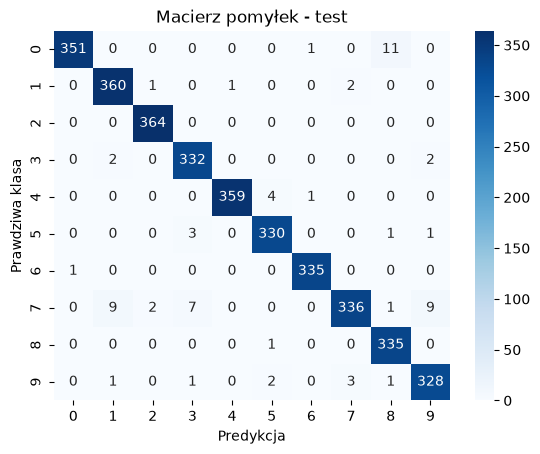

In [44]:
final_model = best_models["SVM (RBF)"]
y_pred = final_model.predict(X_test)
print(classification_report(y_test, y_pred, digits=3))

sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predykcja"); plt.ylabel("Prawdziwa klasa"); plt.title("Macierz pomyłek - test")
plt.show()

### **Wnioski**

- Wybór modelu był oparty na CV, nie na teście. Na teście tylko raportuje wyniki więc nie ma wycieku.
- Regresja logistyczna jest najmniejsza i najszybsza w predykcji, ale robi około 4 razy więcej błędów niż SVM. Granice między klasami są nieliniowe.
- Random Forest jest największy i najwolniej się uczy, a mimo to jest gorszy od kNN i SVM. Jego złożoność się tu nie opłaca.
- kNN osiągnął drugi najlepszy wynik i trenuje się natychmiast, bo jedynie zapamiętuje wszystkie próbki treningowe, przez co jest jednak ponad 5 razy większy od SVM i przy każdej predykcji musi porównać nową próbkę z całym zbiorem.
- SVM ma najlepszy wynik przy umierkowanym rozmiarze, bo zapamiętuje tylko 13% (961) próbek jako wektory nośne. Przejście z regresji logistycznej na SVM daje duży zysk 294 -> 68 błędów czyli o ponad 75% mniej, przy wciąż małym koszcie. Opłaca się. Natomiast bardziej złożony RF już się nie opłaca.

Z narzędzi użyto Claude.ai przy pomiarze złożoności modeli (m.in. w jaki sposób wyciągnąć te informacje z każdego modelu).

## Oddanie zadania

Zapisz kod, wyniki, wykresy i krótkie uzasadnienia w tym notatniku. Podaj użyte źródła oraz narzędzia AI i upewnij się, że notatnik można uruchomić od początku do końca. Wykonaj commit po zakończeniu zadania aby znalazł się na repozytorium.